# TIỀN XỬ LÝ DỮ LIỆU

In [1]:
import numpy as np
import pandas as pd

DATA_PATH = "../../Lab01/2/sp500_yahoo.csv"
df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

df['Return'] = df['Close'].pct_change()
df['Vol_5d'] = df['Return'].rolling(5).std()
df['MA5'] = df['Close'].rolling(5).mean()
df['MA20'] = df['Close'].rolling(20).mean()
df['Next_Close'] = df['Close'].shift(-1)
df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

feature_cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'Return', 'MA5', 'MA20', 'Vol_5d']
X = df[feature_cols].values
y = df['Next_Close'].values

X = (X - X.mean(axis=0)) / X.std(axis=0)

split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (19826, 9), X_test shape: (4957, 9)


# HUẤN LUYỆN MÔ HÌNH THƯ VIỆN SCIKIT-LEARN

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

model_sklearn = LinearRegression()
model_sklearn.fit(X_train, y_train)

y_pred_sklearn = model_sklearn.predict(X_test)
mse_sk = mean_squared_error(y_test, y_pred_sklearn)
rmse_sk = np.sqrt(mse_sk)
mae_sk = mean_absolute_error(y_test, y_pred_sklearn)
r2_sk = r2_score(y_test, y_pred_sklearn)

# SO SÁNH VỚI MÔ HÌNH NUMPY THỦ CÔNG

In [3]:
class LinearRegressionNumpy:
    def fit(self, X, y):
        X_b = np.hstack([np.ones((len(X), 1)), X])
        beta = np.linalg.pinv(X_b.T @ X_b) @ (X_b.T @ y)
        self.b = beta[0]
        self.w = beta[1:]
        return self

    def predict(self, X):
        return X @ self.w + self.b

model_numpy = LinearRegressionNumpy().fit(X_train, y_train)
y_pred_numpy = model_numpy.predict(X_test)

mse_np = mean_squared_error(y_test, y_pred_numpy)
rmse_np = np.sqrt(mse_np)
mae_np = mean_absolute_error(y_test, y_pred_numpy)
r2_np = r2_score(y_test, y_pred_numpy)

diff_intercept = np.abs(model_numpy.b - model_sklearn.intercept_)
diff_coef_max = np.max(np.abs(model_numpy.w - model_sklearn.coef_))

print("=" * 60)
print("SO SÁNH NUMPY THỦ CÔNG VS SCIKIT-LEARN (Bài 4):")
print(f"- Sai lệch Intercept (Bias) : {diff_intercept:.2e}")
print(f"- Sai lệch Coef lớn nhất    : {diff_coef_max:.2e}")
print(f"- NumPy OLS (Thủ công)      : MSE={mse_np:.4f}, RMSE={rmse_np:.4f}, R2={r2_np:.4f}")
print(f"- Scikit-Learn (Thư viện)   : MSE={mse_sk:.4f}, RMSE={rmse_sk:.4f}, R2={r2_sk:.4f}")
print("=" * 60)

SO SÁNH NUMPY THỦ CÔNG VS SCIKIT-LEARN (Bài 4):
- Sai lệch Intercept (Bias) : 7.73e-12
- Sai lệch Coef lớn nhất    : 1.55e-07
- NumPy OLS (Thủ công)      : MSE=1170.2773, RMSE=34.2093, R2=0.9996
- Scikit-Learn (Thư viện)   : MSE=1170.2773, RMSE=34.2093, R2=0.9996


# VẼ ĐỒ THỊ

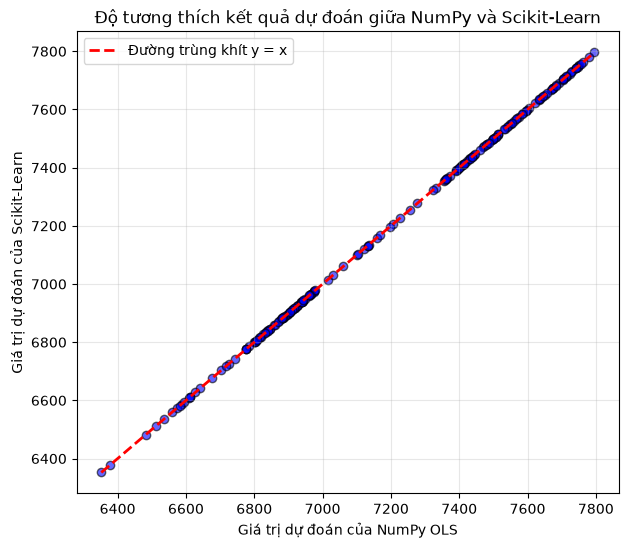

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.scatter(y_pred_numpy[-200:], y_pred_sklearn[-200:], color='blue', alpha=0.6, edgecolors='k')
min_val = min(y_pred_numpy[-200:].min(), y_pred_sklearn[-200:].min())
max_val = max(y_pred_numpy[-200:].max(), y_pred_sklearn[-200:].max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label="Đường trùng khít y = x")
plt.xlabel("Giá trị dự đoán của NumPy OLS")
plt.ylabel("Giá trị dự đoán của Scikit-Learn")
plt.title("Độ tương thích kết quả dự đoán giữa NumPy và Scikit-Learn")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()